# WO3 HMF reaction-network review

## Problem
Infer eleven nonnegative kinetic rates and fifteen molecular concentration trajectories from three author experimental repeats of five HPLC assays and electrical chronocoulometry. These are measured, processed author observations; **no actual physical truth exists**. The independently executed physically corrected source fit is a method reference, not unchanged author reproduction. A near-zero fitted degradation pathway is weakly identifiable and must not be interpreted as absent chemistry.

## Source correction and scientific quality
The original implementation incorrectly counted cumulative known-species electrons as0,2,4,6,8. This task explicitly corrects that formula and subtracts initial charge. Both full pathways transfer6e. Unknown byproducts retain a declared2e-per-layer model assumption. The original single0.05 start then reached objective61.19; six uniform starts avoid that local minimum and reach4.94921714, improving on the erroneous model7.50403. Original wrong-model results and failed corrected starts are preserved privately. No acceptance boundary was relaxed.

In [1]:
from pathlib import Path
import sys, time, json, hashlib, subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,preprocess
from src.physics_model import SPECIES,RATE_NAMES,concentrations,charge
from src.solvers import reconstruct
from src.visualization import plot_observations,plot_hidden_and_residuals,plot_ablation
raw=load_data(ROOT/'data/raw_data.npz'); c,q,initial=preprocess(raw)
print('Observation shapes:',{k:v.shape for k,v in raw.items()})
print('Raw SHA256:',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print('Actual notebook interpreter:',sys.executable)

Observation shapes: {'concentration_repeats': (3, 30, 6), 'charge_repeats': (3, 3000, 2)}
Raw SHA256: d65fee3f25c7f80e4f87c257e9691ce8673d7f527ebf7c6b2c8116fe2a12688b
Actual notebook interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


## Data
All 30 concentration rows through 65 hours and all 3000 charge rows through 64 hours are retained in fitting. Each acquisition has its own time column. Same-index rows are averaged with the original compensated summation. The initial five measured concentrations are fixed; ten unobserved initial pools are zero. The author experiment uses a WO3 photoanode, aqueous pH 4 electrolyte and nominal 5 mmol/L HMF; the charge model uses a 0.1 L volume. Units below are hours, micromol/L and coulombs.

## Physics
Let u contain HMF, DFF, HMFCA, FFCA and FDCA. The first oxidation pathway is HMF→DFF→FFCA→FDCA; a competing branch is HMF→HMFCA→FFCA. Five first degradation pools v receive material from the corresponding tracked species, then convert to final pools w. Rates (a,b,d,e,f,g,h,i,j,k,l) have units h⁻¹. The complete conservation law is sum(u+v+w)=initial molecular concentration. For example du0/dt=−(a+b+g)u0, du3/dt=d u1+e u2−(f+j)u3, dv(r)/dt=s(r)u(r)−l v(r), dw(r)/dt=l v(r), with s=(g,h,i,j,k). Electrical charge is Q(t)=F V 10⁻⁶ sum(n(m)[c(m,t)−c(m,0)]). Known-species electron equivalents are(0,2,2,4,6), making every primary arrow2e and both complete routes6e. Unknown pools assume an additional2e per layer, a phenomenological assumption because their structures are unknown. This corrects a confirmed upstream index-count error and initial-charge offset. F is the Faraday constant and V=0.1L.

## Method
Integrate explicit mass-action equations using original-default LSODA/odeint. Minimize all chemical and electrical residuals jointly, r=(observed−predicted)/(observed+predicted), zero when both vanish, without a sample-count or variance factor. Run six independent uniform starts0.005,0.01,0.025,0.05,0.1,0.2 h⁻¹ and retain the lowest objective; enforce nonnegativity by the original transform k=sqrt(z²+1)−1. Levenberg–Marquardt uses ftol=xtol=1.5e−8, epsfcn=1e−10 and gtol=0. The following cell computes the **complete fresh benchmark reconstruction**; no cache-preview path replaces it.

In [2]:
start=time.perf_counter()
fresh,info=reconstruct(c,q,initial)
fit_runtime=time.perf_counter()-start
print('Fresh full joint fit:',info,'runtime_s=',fit_runtime)
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_notebook_result.npz',**fresh)
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False))
for name,value,original in zip(RATE_NAMES,fresh['rates'][0],upstream['rates']): print(f'{name:6s} fresh={value:.12g} original={original:.12g} 1/h')

Fresh full joint fit: {'nfev': 252, 'status': 1, 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000', 'objective': 4.949217144795996} runtime_s= 16.11846919998061
k11    fresh=0.0057904074 original=0.0057904074 1/h
k12    fresh=0.00193055415234 original=0.00193055415234 1/h
k21    fresh=0.0750553504468 original=0.0750553504468 1/h
k22    fresh=0.0370813311762 original=0.0370813311762 1/h
k3     fresh=0.00594690334741 original=0.00594690334741 1/h
kD1    fresh=0.0331345952963 original=0.0331345952963 1/h
kD21   fresh=0.028034725234 original=0.028034725234 1/h
kD22   fresh=3.97928801021e-10 original=3.97928801021e-10 1/h
kD3    fresh=0.0656338041583 original=0.0656338041583 1/h
kD4    fresh=0.0564893160049 original=0.0564893160049 1/h
kDx    fresh=0.00496901698008 original=0.00496901698008 1/h


## Results
The first figure retains all five tracked chemical species and the electrical measurement comparison from the author notebook. Grey points/curves are three experimental repeats, dashed curves are this task’s independently executed corrected original method, and colored curves are the fresh cleaned-code result. These are not paper-reported historical values or ground truth.

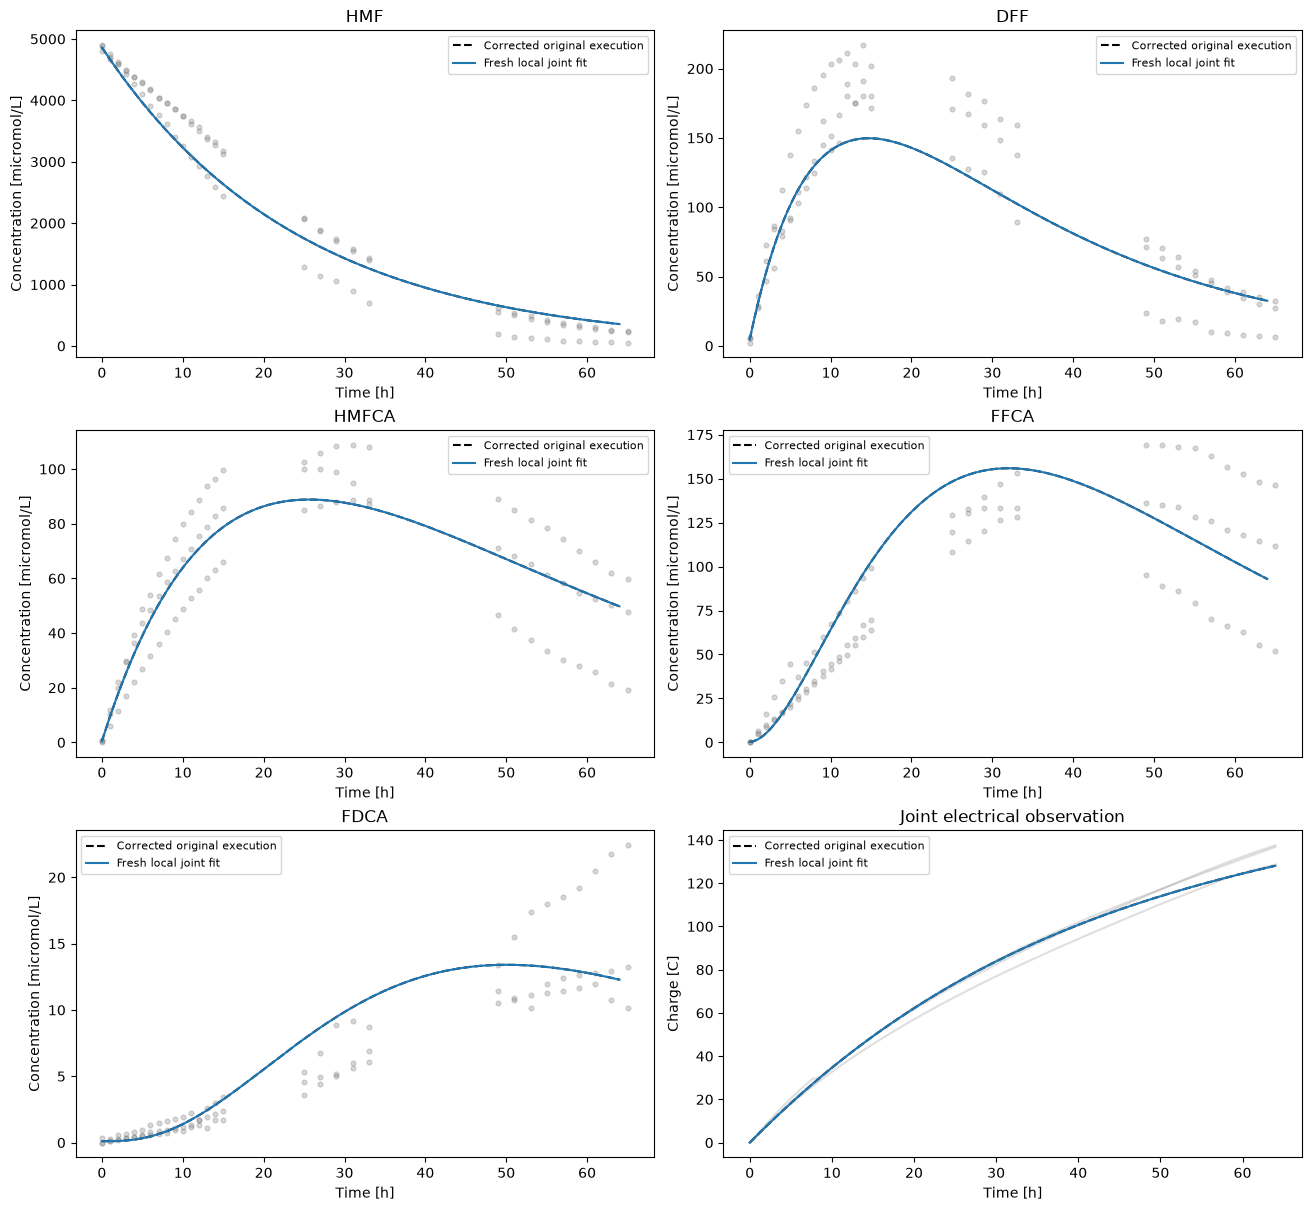

In [3]:
fig=plot_observations(c,q,initial,fresh,upstream,raw)
fig.savefig(ROOT/'notebooks/reference_outputs/observations_and_fit.png',dpi=140)
plt.show()

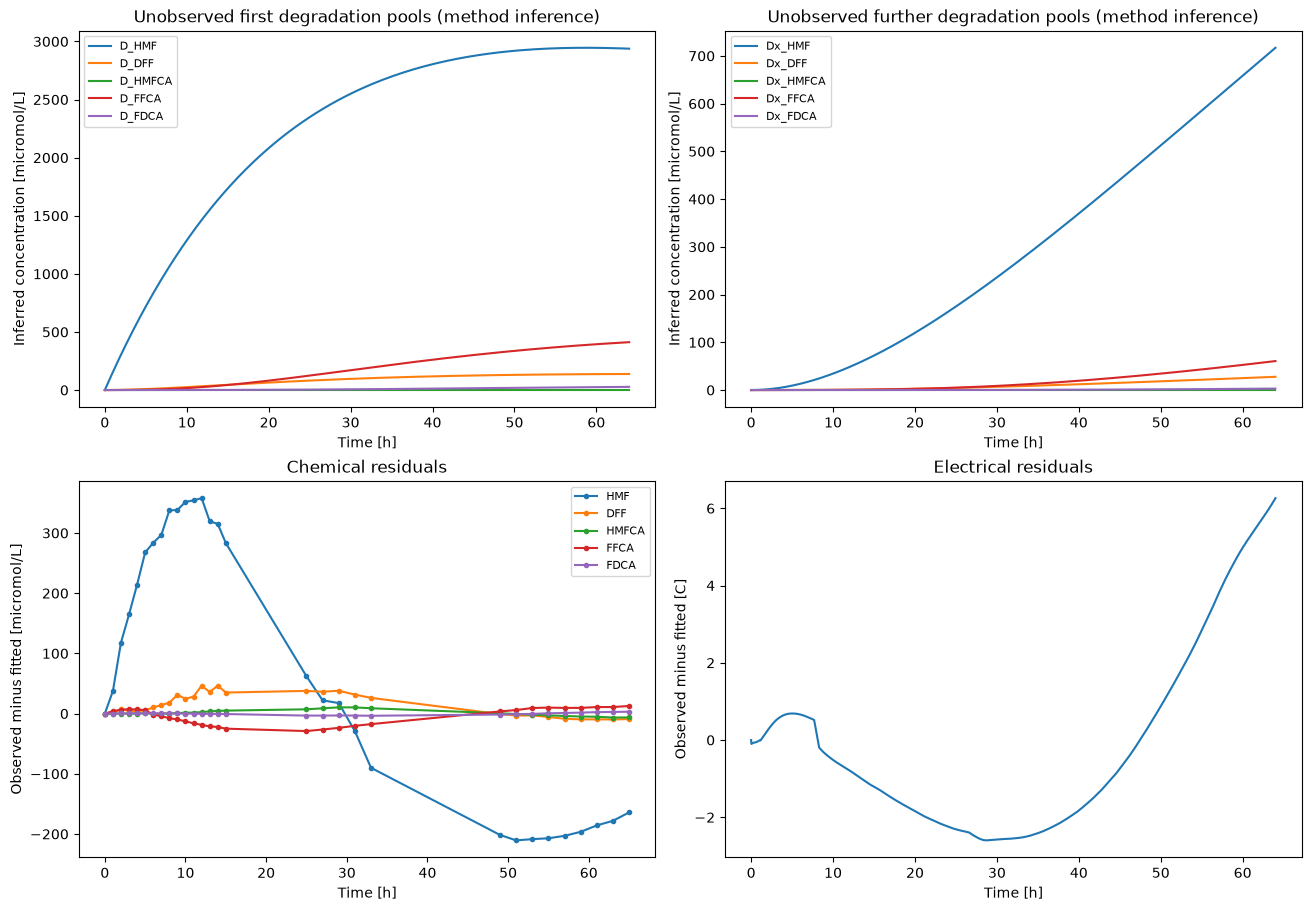

Mass-balance maximum error [micromol/L]: 8.185452315956354e-12
Minimum concentration [micromol/L]: 0.0


In [4]:
fig=plot_hidden_and_residuals(c,q,initial,fresh)
fig.savefig(ROOT/'notebooks/reference_outputs/hidden_and_residuals.png',dpi=140)
plt.show()
state=fresh['reconstruction'][0]
print('Mass-balance maximum error [micromol/L]:',np.max(abs(state.sum(axis=1)-initial.sum())))
print('Minimum concentration [micromol/L]:',state.min())

### Fresh electrical-constraint ablation
Fit the same chemical observations again while omitting the electrical residual. This is a newly computed ablation, not a replacement for the required joint method. Both fits predict charge using their inferred unobserved pools. The paired rates and charge curves expose the inference supplied by the electrical constraint.

Fresh chemical-only fit: {'nfev': 256, 'status': 1, 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000', 'objective': 2.4173406360533254} runtime_s= 12.367956300033256


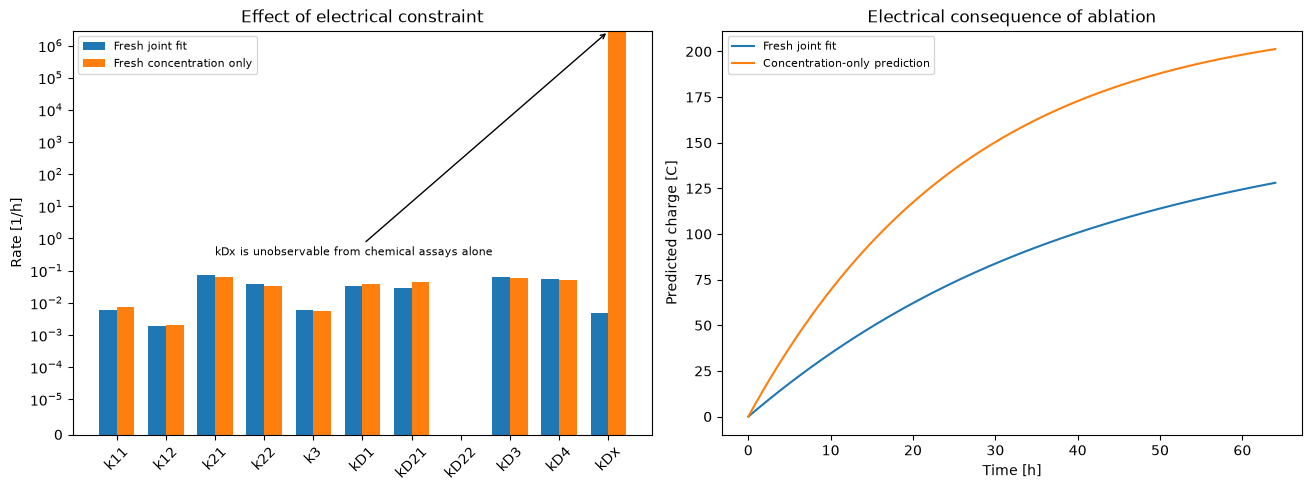

In [5]:
start=time.perf_counter()
chemical_only,chemical_info=reconstruct(c,None,initial)
print('Fresh chemical-only fit:',chemical_info,'runtime_s=',time.perf_counter()-start)
fig=plot_ablation(fresh,chemical_only)
fig.savefig(ROOT/'notebooks/reference_outputs/electrical_ablation.png',dpi=140)
plt.show()

### Identifiability and measurement interpretation
An independently executed upstream profile reoptimizes all other rates while fixing the HMFCA degradation rate. It shows a shallow objective near zero. Multiple successful corrected-original starts reach the same low-objective basin; poor local minima at other starts are disclosed in validation. This figure uses labeled **upstream diagnostic measurements**, not newly claimed notebook fits. The zero-boundary solution is numerically reproducible but has weak chemical identifiability.

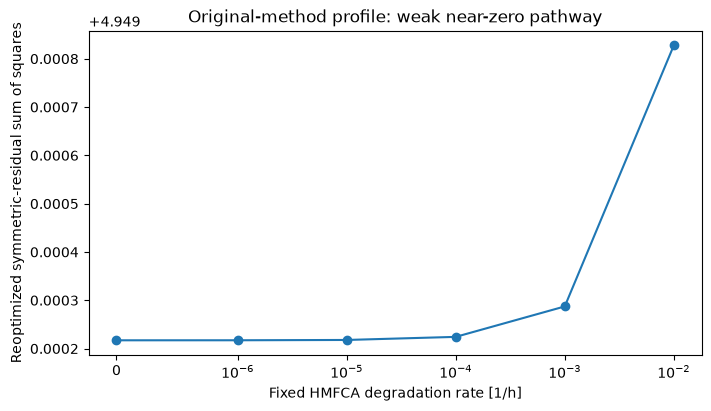

In [6]:
profile=json.loads((ROOT/'notebooks/reference_outputs/upstream_identifiability.json').read_text())
p=[r for r in profile if r['type']=='profile']
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.plot([r['fixed_kD22'] for r in p],[r['objective'] for r in p],'o-')
ax.set_xscale('symlog',linthresh=1e-6)
ax.set(xlabel='Fixed HMFCA degradation rate [1/h]',ylabel='Reoptimized symmetric-residual sum of squares',title='Original-method profile: weak near-zero pathway')
fig.savefig(ROOT/'notebooks/reference_outputs/upstream_profile.png',dpi=140)
plt.show()

### Independent Judge measurement
The standalone Judge evaluates every rate, every concentration trajectory and charge without alignment. The following table gives all measured errors with their declared thresholds. Dynamic-range NRMSE remains defined even for the two tiny near-zero-path pools; no floor was introduced to bypass their failed early parity test. Floating-point fidelity was corrected to preserve the original method.

In [7]:
prediction=ROOT/'notebooks/reference_outputs/fresh_notebook_result.npz'
report=ROOT/'notebooks/reference_outputs/notebook_judge_report.json'
r=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(prediction),'--report',str(report)],capture_output=True,text=True)
assert r.returncode==0,(r.returncode,r.stdout,r.stderr)
record=json.loads(report.read_text())
for name,value in record['metrics'].items(): print(f'{name:30s} {value:.12g} <= {record["thresholds"][name]["boundary"]:.12g}')
assert record['passed']
print('Fresh notebook full fit runtime:',fit_runtime)

rate_0_absolute_error          0 <= 3.15808148e-05
rate_1_absolute_error          0 <= 2.38611083047e-05
rate_2_absolute_error          0 <= 0.000170110700894
rate_3_absolute_error          0 <= 9.41626623524e-05
rate_4_absolute_error          0 <= 3.18938066948e-05
rate_5_absolute_error          0 <= 8.62691905927e-05
rate_6_absolute_error          0 <= 7.6069450468e-05
rate_7_absolute_error          0 <= 2.00000007959e-05
rate_8_absolute_error          0 <= 0.000151267608317
rate_9_absolute_error          0 <= 0.00013297863201
rate_10_absolute_error         0 <= 2.99380339602e-05
species_0_nrmse                0 <= 0.002
species_1_nrmse                0 <= 0.002
species_2_nrmse                0 <= 0.002
species_3_nrmse                0 <= 0.002
species_4_nrmse                0 <= 0.002
species_5_nrmse                0 <= 0.002
species_6_nrmse                0 <= 0.002
species_7_nrmse                0 <= 0.002
species_8_nrmse                0 <= 0.002
species_9_nrmse                0 

## Conclusion
The cleaned local network reproduces the independently verified corrected-source method on all bound experimental observations and satisfies per-output numerical criteria. Hidden degradation pools are model inferences. Electrical sampling contributes its original objective weight; the ablation visualizes this dependence. Residual structure and weak near-zero-path identifiability limit physical interpretation. Conservation, all five balanced two-electron half-reactions, path independence and initial-charge-zero tests complement reference agreement; neither numerical parity nor Judge success establishes a measured physical truth for all rates.